# Notebook 07 — Disagreement Validation and Error Analysis

## Overview

This notebook examines how explanation stability and localization alignment differ between **true-positive (TP)** and **false-negative (FN)** chest X-rays. It builds on the stability–localization audit from Notebook 06 using previously saved results; it does not retrain ResNet-50 or generate new attribution maps.

The analysis uses two CSV files:

- `stability_localization_audit.csv`: one row per annotated positive image, XAI method, and corruption condition, including stability, localization change, model predictions, and disagreement flags.
- `combined_xai_results.csv`: results for original and corrupted images, including the model's predicted positive-class probability.

The notebook first separates annotated positive images by whether the original prediction was correct. It then examines the individual conditions behind the disagreement flag, estimates uncertainty using image-level bootstrap resampling, compares prediction changes and probabilities, and summarizes results by XAI method and corruption condition.

**Interpretation:** The explanations target the model's original predicted class. For a false negative, this is the negative class, so localization alignment with annotated opacity regions must be interpreted differently than for a true positive. The CSV files contain summary measurements, not full attribution maps or bounding-box masks.

**Running in Google Colab:** Mount Google Drive in Section 1 and set `DATA_DIR` to the folder where the CSV files already reside. The notebook may be stored elsewhere. A CPU runtime is sufficient.


## 1. Load and check the data

Mount Google Drive and set `DATA_DIR` to the **existing folder containing the two CSV files**. The code reads the files without moving or copying them.

The checks confirm the expected number of rows, unique images, and repeated evaluations. Each audit row represents one annotated positive image evaluated with one XAI method under one corruption condition; multiple rows from the same image are not independent observations.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mount Google Drive; the notebook and data files can be in different folders.
from google.colab import drive

drive.mount("/content/drive")

DATA_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation"
)
print("Data folder exists:", DATA_DIR.exists())
audit_path = DATA_DIR / "stability_localization_audit.csv"
combined_path = DATA_DIR / "combined_xai_results.csv"
assert audit_path.exists() and combined_path.exists()
audit = pd.read_csv(audit_path)
combined = pd.read_csv(combined_path)
assert audit["sop_uid"].nunique() == 150
assert len(audit) == 2700 and len(combined) == 6300
assert audit["true_class"].eq(1).all()
assert audit.groupby("sop_uid")["original_predicted_class"].nunique().eq(1).all()
assert audit.groupby("sop_uid").size().eq(18).all()
print("Audit:", audit.shape, "| images:", audit.sop_uid.nunique())
print("Combined:", combined.shape, "| images:", combined.sop_uid.nunique())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder exists: True
Audit: (2700, 20) | images: 150
Combined: (6300, 15) | images: 300


## 2. Group images by the original model prediction

All images in the audit have a positive ground-truth label. An image is labeled **true positive** if ResNet-50 originally predicted the positive class, and **false negative** if it originally predicted the negative class.

The next cell counts unique images in each group and summarizes disagreement flags, mean stability, mean localization change, and how often the predicted class changes under corruption. The reported evaluation rates count repeated method–corruption measurements, not distinct patients.


In [2]:
audit["prediction_group"] = np.where(
    audit["original_predicted_class"].eq(1), "True positive", "False negative"
)
image_groups = audit[["sop_uid", "prediction_group"]].drop_duplicates()
print("Unique images by group:")
print(image_groups.prediction_group.value_counts().to_string())
summary = audit.groupby("prediction_group").agg(
    images=("sop_uid", "nunique"),
    evaluations=("disagreement", "size"),
    flagged=("disagreement", "sum"),
    mean_stability=("explanation_similarity", "mean"),
    mean_alignment_change=("alignment_change", "mean"),
    prediction_change_rate=("prediction_changed", "mean"),
)
summary["disagreement_rate"] = summary["flagged"] / summary["evaluations"]
print(summary.round(4).to_string())

Unique images by group:
prediction_group
True positive     128
False negative     22
                  images  evaluations  flagged  mean_stability  mean_alignment_change  prediction_change_rate  disagreement_rate
prediction_group                                                                                                                
False negative        22          396        2          0.6411                 -0.016                  0.7197             0.0051
True positive        128         2304      169          0.6837                 -0.078                  0.0013             0.0734



### Interpretation of Prediction Groups

Among the 150 annotated-positive chest X-rays, the model originally classified 128 as positive (true positives) and 22 as negative (false negatives).

The disagreement rate was 7.34% for true-positive evaluations (169/2,304) and 0.51% for false-negative evaluations (2/396).

True positives also had a larger average decrease in localization alignment (-0.078) than false negatives (-0.016).

These differences should be interpreted in relation to the explanation target. True-positive explanations target the positive class, whereas false-negative explanations target the negative class. Both are evaluated against the annotated positive-opacity regions.

Therefore, a lower disagreement rate for false negatives does not necessarily indicate more reliable explanations.


## 3. Examine the components of the disagreement flag

An evaluation is flagged when **both** conditions are met:

- Spearman explanation stability is at least **0.80**.
- Localization alignment decreases by at least **0.05** relative to the original image.

The next cell reports how often each condition occurs separately, as well as how often both occur together. This helps distinguish a low joint disagreement rate caused by low stability from one caused by infrequent localization loss.


                  high_stability_rate  localization_loss_rate  joint_disagreement_rate  mean_spearman  mean_alignment_change
prediction_group                                                                                                            
False negative                 0.3081                  0.2146                   0.0051         0.6411                 -0.016
True positive                  0.4141                  0.4601                   0.0734         0.6837                 -0.078


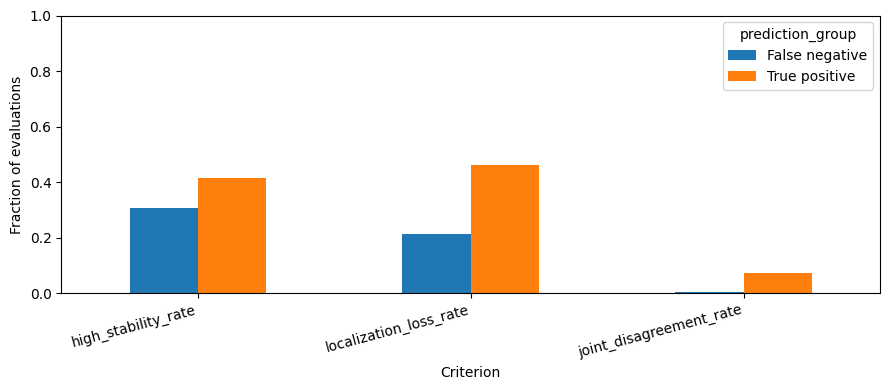

In [3]:
component_summary = audit.groupby("prediction_group").agg(
    high_stability_rate=("high_stability", "mean"),
    localization_loss_rate=("localization_loss", "mean"),
    joint_disagreement_rate=("disagreement", "mean"),
    mean_spearman=("explanation_similarity", "mean"),
    mean_alignment_change=("alignment_change", "mean"),
)
print(component_summary.round(4).to_string())
ax = component_summary[
    ["high_stability_rate", "localization_loss_rate", "joint_disagreement_rate"]
].T.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("Fraction of evaluations")
ax.set_ylim(0, 1)
ax.set_xlabel("Criterion")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 4. Estimate uncertainty with an image-level bootstrap

Each annotated image appears in 18 audit rows (three explanation methods × six corruption conditions). Resampling individual rows would ignore this repeated-measure structure.

Instead, the next cell calculates each image's disagreement proportion and resamples **images** within the true-positive and false-negative groups. It repeats this procedure 5,000 times to estimate 95% percentile bootstrap confidence intervals for each group's disagreement rate and their difference.

The false-negative group contains fewer images, so its interval may be relatively uncertain. These intervals describe variation under this sampling and analysis procedure; they do not establish clinical generalizability.


In [4]:
rng = np.random.default_rng(2026)
B = 5000
per_image = (
    audit.groupby(["prediction_group", "sop_uid"])["disagreement"].mean().reset_index()
)
boot = {}
for group, frame in per_image.groupby("prediction_group"):
    rates = frame["disagreement"].to_numpy()
    draws = rng.choice(rates, size=(B, len(rates)), replace=True).mean(axis=1)
    boot[group] = draws
    print(
        f"{group}: rate={rates.mean():.4f}, 95% bootstrap CI={np.quantile(draws,[.025,.975]).round(4)}; n_images={len(rates)}"
    )
diff = boot["True positive"] - boot["False negative"]
print(
    "TP − FN rate difference:",
    round(
        per_image.query("prediction_group == 'True positive'")["disagreement"].mean()
        - per_image.query("prediction_group == 'False negative'")[
            "disagreement"
        ].mean(),
        4,
    ),
)
print(
    "95% stratified cluster-bootstrap CI for difference:",
    np.quantile(diff, [0.025, 0.975]).round(4),
)

False negative: rate=0.0051, 95% bootstrap CI=[0.     0.0152]; n_images=22
True positive: rate=0.0734, 95% bootstrap CI=[0.0577 0.0894]; n_images=128
TP − FN rate difference: 0.0683
95% stratified cluster-bootstrap CI for difference: [0.0496 0.0864]



### Interpretation of Bootstrap Results

The estimated disagreement rate was 7.34% for true positives, with a 95% bootstrap confidence interval of 5.77% to 8.94%.

For false negatives, the estimated rate was 0.51%, with an interval of 0% to 1.52%.

The estimated difference between the groups was 6.83 percentage points, with a 95% bootstrap interval of 4.96 to 8.64 percentage points.

The bootstrap resamples images rather than individual evaluations, preserving the repeated-measure structure within each image.

These intervals describe uncertainty under the current sampling and evaluation procedure. The false-negative group contains only 22 images, and the intervals do not account for all possible sources of uncertainty, including model training and dataset selection.


## 5. Examine prediction changes and positive-class probability

The `opacity_probability` field represents the model's estimated probability of the **positive** class. It should not be interpreted as confidence in whichever class the model predicted.

The next cell matches each corrupted evaluation with the corresponding original image and XAI method, then calculates the change in positive-class probability. It summarizes how often the predicted class changes, the average probability change, and the disagreement rate for each prediction group.


In [5]:
original = combined.loc[
    combined.corruption.eq("Original"), ["sop_uid", "method", "opacity_probability"]
].rename(columns={"opacity_probability": "original_opacity_probability"})
assert not original.duplicated(["sop_uid", "method"]).any()
confidence = audit.merge(
    original, on=["sop_uid", "method"], how="left", validate="many_to_one"
)
assert confidence.original_opacity_probability.notna().all()
confidence["opacity_probability_change"] = (
    confidence.opacity_probability - confidence.original_opacity_probability
)
print(
    confidence.groupby("prediction_group")
    .agg(
        prediction_change_rate=("prediction_changed", "mean"),
        mean_probability_change=("opacity_probability_change", "mean"),
        mean_absolute_probability_change=(
            "opacity_probability_change",
            lambda x: x.abs().mean(),
        ),
        disagreement_rate=("disagreement", "mean"),
    )
    .round(4)
    .to_string()
)
print("\nJoint flag by prediction changed (descriptive):")
print(
    confidence.groupby(["prediction_group", "prediction_changed"])
    .agg(n=("disagreement", "size"), flag_rate=("disagreement", "mean"))
    .round(4)
    .to_string()
)

                  prediction_change_rate  mean_probability_change  mean_absolute_probability_change  disagreement_rate
prediction_group                                                                                                      
False negative                    0.7197                   0.2495                            0.2496             0.0051
True positive                     0.0013                  -0.0976                            0.1191             0.0734

Joint flag by prediction changed (descriptive):
                                        n  flag_rate
prediction_group prediction_changed                 
False negative   0                    111     0.0000
                 1                    285     0.0070
True positive    0                   2301     0.0734
                 1                      3     0.0000



### Interpretation of Prediction Changes

The predicted class changed in 285 of 396 false-negative evaluations (71.97%), compared with 3 of 2,304 true-positive evaluations (0.13%).

For false negatives, the mean positive-class probability increased by approximately 0.250 after corruption. For true positives, it decreased by approximately 0.098.

These results suggest that the model's original false-negative predictions were more sensitive to the tested image corruptions.

However, the explanations were generated for the original predicted class, even when the model's prediction changed. Consequently, explanation stability measures the consistency of attribution for a fixed target class, not necessarily the explanation of the corrupted image's new predicted class.

The reported prediction-change rates also represent repeated evaluations across explanation methods and corruption conditions, rather than independent images.


## 6. Compare XAI methods and corruption conditions

The next cell breaks down disagreement rates by original prediction group, XAI method, corruption type, and severity. It also reports the mean stability and localization change within each subgroup.

These summaries show whether pooled differences are concentrated in particular methods or corruption conditions. Rates are calculated using the number of evaluations in each subgroup.


In [6]:
by_condition = (
    audit.groupby(
        ["prediction_group", "method", "corruption", "severity"], observed=True
    )
    .agg(
        images=("sop_uid", "nunique"),
        flagged=("disagreement", "sum"),
        evaluations=("disagreement", "size"),
        mean_stability=("explanation_similarity", "mean"),
        mean_alignment_change=("alignment_change", "mean"),
    )
    .reset_index()
)
by_condition["disagreement_rate"] = by_condition.flagged / by_condition.evaluations
print(
    by_condition.sort_values(["prediction_group", "method", "corruption", "severity"])
    .round(3)
    .to_string(index=False)
)

prediction_group                method corruption severity  images  flagged  evaluations  mean_stability  mean_alignment_change  disagreement_rate
  False negative  Integrated Gradients       Blur     mild      22        0           22           0.855                 -0.002              0.000
  False negative  Integrated Gradients       Blur moderate      22        0           22           0.620                 -0.026              0.000
  False negative  Integrated Gradients       Blur   severe      22        0           22           0.539                 -0.037              0.000
  False negative  Integrated Gradients      Noise     mild      22        0           22           0.606                 -0.028              0.000
  False negative  Integrated Gradients      Noise moderate      22        0           22           0.509                 -0.052              0.000
  False negative  Integrated Gradients      Noise   severe      22        0           22           0.373              


## 7. Validation of Disagreement Flags

This section checks whether the disagreement indicators in the saved audit dataset are consistent with the criteria used in Notebook 06.

An evaluation is classified as a disagreement when both conditions are satisfied:

- Explanation stability (Spearman correlation) is at least 0.80.
- Localization alignment decreases by at least 0.05 relative to the original image.

The indicators are recalculated from the numerical columns and compared with the saved flags. This helps identify possible inconsistencies before proceeding with additional analyses.


In [7]:
import numpy as np
import pandas as pd

# Use the audit DataFrame loaded earlier in Notebook 07.
# Change this name if your existing DataFrame is different.
df = audit.copy()

# Recalculate the three indicators
df["recalculated_high_stability"] = df["explanation_similarity"] >= 0.80

df["recalculated_localization_loss"] = df["alignment_change"] <= -0.05

df["recalculated_disagreement"] = (
    df["recalculated_high_stability"] & df["recalculated_localization_loss"]
)

# Compare recalculated indicators with saved values
for original, recalculated in [
    ("high_stability", "recalculated_high_stability"),
    ("localization_loss", "recalculated_localization_loss"),
    ("disagreement", "recalculated_disagreement"),
]:
    mismatches = (df[original] != df[recalculated]).sum()

    print(f"{original}: {mismatches} mismatches")

high_stability: 0 mismatches
localization_loss: 0 mismatches
disagreement: 0 mismatches



## 8. Image-Level Disagreement Analysis

The preceding analyses report disagreement rates across repeated evaluations of the same chest X-rays.

Each image contributes 18 evaluations, corresponding to three XAI methods and six corruption conditions. Therefore, the number of flagged evaluations does not represent the number of distinct images exhibiting disagreement.

This section calculates the proportion of unique images that experienced at least one disagreement under any evaluated method or corruption condition.

An image is counted once if at least one of its evaluations satisfies the disagreement criteria.


In [8]:
# Identify true positives and false negatives
positive_df = df[df["true_class"] == 1].copy()

positive_df["prediction_group"] = np.where(
    positive_df["original_predicted_class"] == 1, "True Positive", "False Negative"
)

# One row per image
image_summary = (
    positive_df.groupby(["prediction_group", "sop_uid"])["disagreement"]
    .any()
    .reset_index(name="any_disagreement")
)

# Summarize by prediction group
image_results = (
    image_summary.groupby("prediction_group")
    .agg(
        total_images=("sop_uid", "nunique"),
        images_with_disagreement=("any_disagreement", "sum"),
    )
    .reset_index()
)

image_results["percentage"] = (
    100 * image_results["images_with_disagreement"] / image_results["total_images"]
)

display(image_results)

,prediction_group,total_images,images_with_disagreement,percentage
0,False Negative,22,1,4.545455
1,True Positive,128,69,53.906250



### Interpretation

Among the 128 true-positive images, 69 (53.91%) experienced at least one disagreement across the evaluated XAI methods and corruption conditions.

Among the 22 false-negative images, one (4.55%) experienced at least one disagreement.

These results describe image-level disagreement prevalence rather than the proportion of individual evaluations flagged.

The findings indicate that disagreement occurs across multiple true-positive images. However, the image-level measure does not indicate how frequently each affected image was flagged.

The interpretation of the true-positive and false-negative results also differs because explanations target the original predicted class, while localization is evaluated against positive-opacity annotations.



## 9. Sensitivity to Disagreement Thresholds

The primary disagreement definition uses a Spearman stability threshold of 0.80 and a minimum localization alignment decrease of 0.05.

These thresholds are exploratory rather than established clinical or statistical standards.

This section evaluates how the observed disagreement rates change under alternative threshold combinations.

Three stability thresholds (0.70, 0.80, and 0.90) and three localization loss thresholds (0.03, 0.05, and 0.10) are considered.

The analysis helps determine whether the observed disagreement patterns are specific to the original threshold combination.


In [9]:
stability_thresholds = [0.70, 0.80, 0.90]
loss_thresholds = [0.03, 0.05, 0.10]

results = []

for stability_threshold in stability_thresholds:
    for loss_threshold in loss_thresholds:

        flag = (positive_df["explanation_similarity"] >= stability_threshold) & (
            positive_df["alignment_change"] <= -loss_threshold
        )

        for group in ["True Positive", "False Negative"]:
            group_mask = positive_df["prediction_group"] == group

            group_flags = flag[group_mask]

            results.append(
                {
                    "prediction_group": group,
                    "stability_threshold": stability_threshold,
                    "loss_threshold": loss_threshold,
                    "flagged_evaluations": int(group_flags.sum()),
                    "total_evaluations": len(group_flags),
                    "disagreement_rate": (100 * group_flags.mean()),
                }
            )

threshold_results = pd.DataFrame(results)

display(
    threshold_results.sort_values(
        ["prediction_group", "stability_threshold", "loss_threshold"]
    )
)

,prediction_group,stability_threshold,loss_threshold,flagged_evaluations,total_evaluations,disagreement_rate
1,False Negative,0.7,0.03,15,396,3.787879
3,False Negative,0.7,0.05,7,396,1.767677
5,False Negative,0.7,0.10,1,396,0.252525
7,False Negative,0.8,0.03,7,396,1.767677
9,False Negative,0.8,0.05,2,396,0.505051
11,False Negative,0.8,0.10,0,396,0.000000
13,False Negative,0.9,0.03,1,396,0.252525
15,False Negative,0.9,0.05,0,396,0.000000
17,False Negative,0.9,0.10,0,396,0.000000
0,True Positive,0.7,0.03,414,2304,17.968750


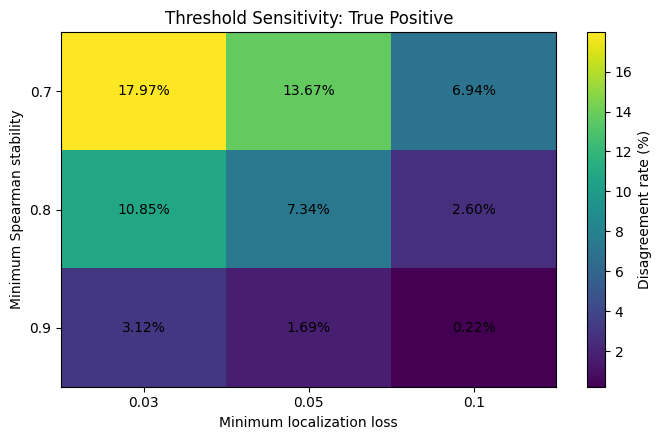

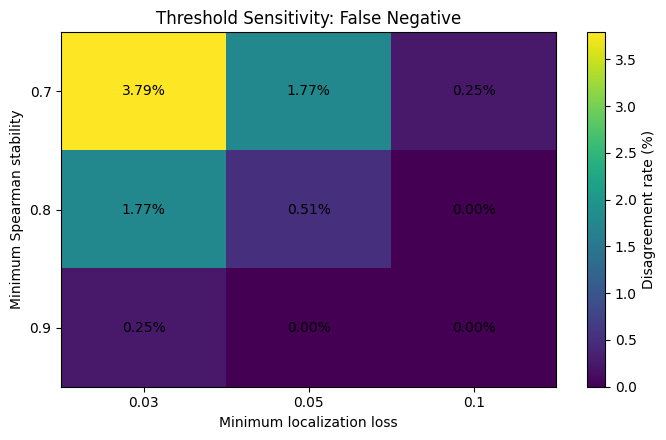

In [10]:
import matplotlib.pyplot as plt

for group in ["True Positive", "False Negative"]:

    subset = threshold_results[threshold_results["prediction_group"] == group]

    pivot = subset.pivot(
        index="stability_threshold",
        columns="loss_threshold",
        values="disagreement_rate",
    )

    fig, ax = plt.subplots(figsize=(7, 4.5))

    im = ax.imshow(pivot.values, aspect="auto")

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)

    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)

    ax.set_xlabel("Minimum localization loss")
    ax.set_ylabel("Minimum Spearman stability")
    ax.set_title(f"Threshold Sensitivity: {group}")

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            ax.text(j, i, f"{pivot.values[i, j]:.2f}%", ha="center", va="center")

    fig.colorbar(im, ax=ax, label="Disagreement rate (%)")

    plt.tight_layout()
    plt.show()


### Interpretation

The disagreement rate depends on the selected stability and localization loss thresholds.

Increasing the minimum stability threshold restricts the analysis to explanations that remain more similar after corruption. Increasing the minimum localization loss threshold restricts the analysis to larger decreases in attribution alignment.

As both criteria become more restrictive, fewer evaluations satisfy the joint disagreement definition.

The original thresholds of 0.80 and 0.05 are retained for consistency with Notebook 06. The alternative combinations provide a sensitivity analysis rather than replacing the original definition.

Differences between true positives and false negatives should also be interpreted in the context of the fixed explanation target: false-negative explanations target the model's originally predicted negative class, while localization is measured against positive-opacity annotations.



## 10. Prediction Changes by Corruption Condition

The preceding analysis showed a substantial difference in prediction-change rates between true-positive and false-negative evaluations.

This section examines whether those changes are concentrated in particular corruption types and severity levels.

For each original prediction group and corruption condition, the analysis calculates the proportion of unique images whose predicted class differs from the original prediction.

Because model predictions do not depend on the explanation method, each image-corruption condition is counted once, avoiding duplicate predictions across the three XAI methods.


In [11]:
# Verify prediction-change consistency across XAI methods
prediction_consistency = audit.groupby(["sop_uid", "corruption", "severity"])[
    "prediction_changed"
].nunique()

assert prediction_consistency.eq(
    1
).all(), "Prediction-change indicators differ across XAI methods."

print("Prediction-change indicators are consistent across XAI methods.")

Prediction-change indicators are consistent across XAI methods.


In [12]:
# Keep one prediction record per image and corruption condition.
prediction_data = audit[
    ["sop_uid", "prediction_group", "corruption", "severity", "prediction_changed"]
].drop_duplicates()

# Verify that each image-condition combination appears once.
assert not prediction_data.duplicated(["sop_uid", "corruption", "severity"]).any()

# Summarize prediction changes.
prediction_by_condition = (
    prediction_data.groupby(
        ["prediction_group", "corruption", "severity"], observed=True
    )
    .agg(
        images=("sop_uid", "nunique"),
        changed=("prediction_changed", "sum"),
        change_rate=("prediction_changed", "mean"),
    )
    .reset_index()
)

prediction_by_condition["change_rate_pct"] = (
    prediction_by_condition["change_rate"] * 100
)

display(
    prediction_by_condition.sort_values(["prediction_group", "corruption", "severity"])
)

,prediction_group,corruption,severity,images,changed,change_rate,change_rate_pct
0,False negative,Blur,mild,22,3,0.136364,13.636364
1,False negative,Blur,moderate,22,18,0.818182,81.818182
2,False negative,Blur,severe,22,22,1.000000,100.000000
3,False negative,Noise,mild,22,14,0.636364,63.636364
4,False negative,Noise,moderate,22,16,0.727273,72.727273
5,False negative,Noise,severe,22,22,1.000000,100.000000
6,True positive,Blur,mild,128,0,0.000000,0.000000
7,True positive,Blur,moderate,128,0,0.000000,0.000000
8,True positive,Blur,severe,128,0,0.000000,0.000000
9,True positive,Noise,mild,128,0,0.000000,0.000000



### Interpretation

Prediction changes were substantially more frequent among originally false-negative images than among originally true-positive images.

For false negatives, all 22 images changed from a negative to a positive prediction under severe Gaussian blur and severe Gaussian noise. Moderate blur produced prediction changes in 18 of 22 images (81.82%), while mild noise produced changes in 14 of 22 images (63.64%).

For true positives, predictions remained unchanged under five of the six corruption conditions. Only one image changed its prediction under moderate Gaussian noise.

These findings suggest that the original false-negative predictions were particularly sensitive to the tested perturbations, while the original true-positive predictions were comparatively stable.

Because the false-negative images have positive ground-truth labels, a change from negative to positive corresponds to a corrected binary classification for those images. However, this does not establish that corruption improves model performance overall, since originally negative images are not included in this analysis.

The results also do not establish that the model's changed predictions are based on clinically meaningful image features.

Each image contributes one observation per corruption condition in this section, avoiding duplicate predictions across the three XAI methods.

These results characterize prediction changes within a selected subset of annotated-positive images and should not be interpreted as evidence that image corruption improves classifier performance on the full test population.



## 11. Summary and Limitations

This notebook extended the stability–localization disagreement audit by examining differences between true-positive and false-negative chest X-rays.

The analysis produced the following findings:

1. **Disagreement rates:** The joint disagreement criterion was satisfied in 7.34% of true-positive evaluations and 0.51% of false-negative evaluations.

2. **Image-level prevalence:** At least one disagreement occurred in 69 of 128 true-positive images and one of 22 false-negative images.

3. **Prediction sensitivity:** Originally false-negative predictions changed substantially more frequently under the tested corruptions than originally true-positive predictions.

4. **Statistical uncertainty:** Image-level bootstrap resampling was used to estimate uncertainty while preserving the repeated-evaluation structure.

5. **Threshold sensitivity:** The observed disagreement rate varied with the stability and localization loss thresholds, indicating that the chosen thresholds influence the frequency of flagged cases.

### Limitations

- The audit includes 150 annotated-positive images and does not evaluate prediction changes among originally negative images.
- The false-negative subgroup contains only 22 images.
- The disagreement thresholds are exploratory and are not clinically validated criteria.
- Explanations target the original predicted class, including when corruption changes the model's prediction.
- Localization alignment measures attribution concentration inside annotated opacity boxes, not causal faithfulness.
- The results are specific to the evaluated model, XAI methods, and Gaussian corruption conditions.
- Bootstrap intervals do not account for uncertainty from model retraining or alternative dataset selections.

The subsequent analysis will examine localization measurements and selected spatial attribution maps to investigate how explanation patterns change under corruption.
